# BÁO CÁO PHẦN 1 - BÀI 2 (TRANG 30): DỮ LIỆU CẢM BIẾN NHÀ XƯỞNG (TB_TRACKING)
## CÂU 5 (Yêu cầu d.2): Đồ thị phân tán (scatter plot) độ ẩm (humidity) theo minutes
- Vẽ biểu đồ biểu diễn giá trị `humidity` theo trục thời gian `minutes`
- Nhận xét về sự biến thiên độ ẩm không khí


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- THỐNG KÊ CHỈ SỐ ĐỘ ẨM ---
count     1918.000000
mean        74.707508
std        250.568960
min          3.000000
25%         61.000000
50%         70.500000
75%         79.000000
max      11030.000000
Name: humidity, dtype: float64


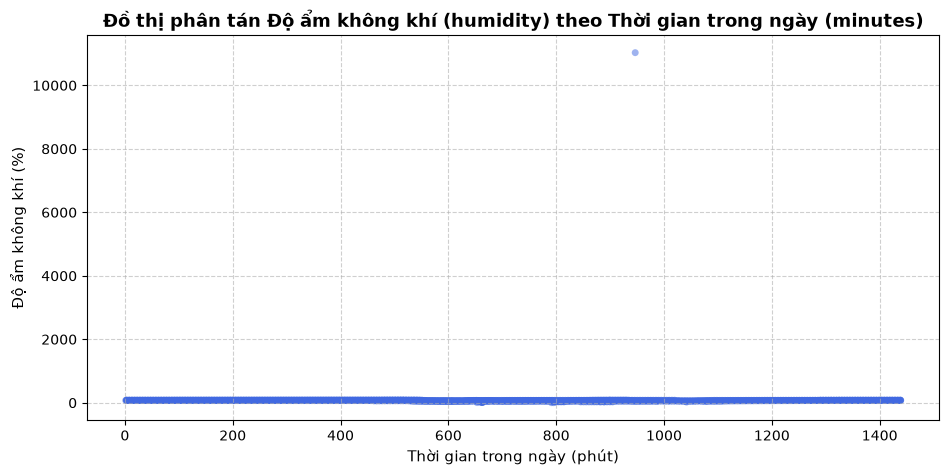

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename


path = get_data_path('tb_tracking.xlsx')
df = pd.read_excel(path, header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df_filtered = df[df['time'] >= '2018-01-03'].copy()
df_filtered['minutes'] = df_filtered['time'].dt.hour * 60 + df_filtered['time'].dt.minute + df_filtered['time'].dt.second / 60.0

plt.figure(figsize=(11, 5))
plt.scatter(df_filtered['minutes'], df_filtered['humidity'], color='royalblue', alpha=0.5, s=25, edgecolors='none')
plt.title("Đồ thị phân tán Độ ẩm không khí (humidity) theo Thời gian trong ngày (minutes)", fontsize=13, fontweight='bold')
plt.xlabel("Thời gian trong ngày (phút)", fontsize=11)
plt.ylabel("Độ ẩm không khí (%)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("--- THỐNG KÊ CHỈ SỐ ĐỘ ẨM ---")
print(df_filtered['humidity'].describe())


### Nhận xét Câu 5:
- Độ ẩm (`humidity`) có sự phân tán rộng, trải dài từ khoảng 3% đến hơn 60%.
- Xu hướng độ ẩm có sự thay đổi rõ rệt theo thời gian:
  * Vào đầu ca chiều (khoảng phút 800 - 1000), độ ẩm dao động khá mạnh và có xu hướng giảm dần khi xưởng hoạt động.
  * Càng về đêm và rạng sáng (sau phút 1200), độ ẩm có xu hướng ổn định và tăng trở lại do nhiệt độ môi trường hạ thấp.
